# Segmentación de clientes Mercedes-Benz con K-Means

Notebook de los **retos 3 y 4 (clustering e interpretación)**. Parte del dataset limpio del EDA (`eda.cleaning.clean`) y trabaja a
**nivel cliente** (una fila por `client_id`), porque lo que se segmenta son clientes, no relaciones cliente–vehículo.

1. Datos de entrada: features por cliente
2. Pipeline (escalado + K-Means)
3. Ejecución de K-Means para un rango de k
4. Método del codo
5. Silhouette Score para cada k
6. Selección y justificación del número óptimo de clusters
7. Modelo final y distribución de clientes
8. Perfil del cliente por cluster (reto 4)

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "clustering").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from eda import cleaning as C
from clustering import pipeline as P

warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
BLUE, RED, GREY = "#1f4e79", "#c0392b", "#9aa5b1"

df = C.load_clean()
print(f"Dataset limpio: {df.shape[0]:,} relaciones cliente-vehículo x {df.shape[1]} columnas")

Dataset limpio: 302,850 relaciones cliente-vehículo x 54 columnas


## 1. Datos de entrada: features por cliente

Se agrega el dataset limpio a una fila por cliente (`eda.cubes.tabla_clientes`). Se usan solo **7 variables numéricas**, cada una con una
lectura de negocio clara y sin nulos:

| Feature | Qué mide | Para qué sirve en marketing |
|---|---|---|
| `edad_cliente` | Punto medio de `age_range` (21, 30, 40… 70) | Perfil generacional |
| `months_as_mb_customer` | Antigüedad como cliente | Fidelización |
| `n_vehiculos` | Nº de vehículos del cliente (tope en 10: flotas) | Particular vs. multi-vehículo vs. flota |
| `edad_vehiculo_mediana` | Años de sus vehículos (tope en 20) | Ciclo de renovación, mantenimiento |
| `pct_electrificados` | % de vehículos eléctricos/híbridos | Afinidad por la electrificación |
| `pct_premium` | % de vehículos de gama alta (S, E, GLE/GLS, G, EQE/EQS, AMG…) | Gama de producto |
| `usa_leasing` | 1 si tiene un leasing activo | Ofertas de financiación/renovación |

El resto (género, país, rol, telemática…) **no entra en el modelo**; se guarda para describir los clusters después. El género es un dato
inferido (ver EDA 6.6) y el país solo tiene dos valores, que partirían los clusters por país en vez de por comportamiento.

In [2]:
X_df = P.client_features(df)
X_in = X_df[P.FEATURES]
print(f"Clientes: {len(X_in):,}  |  features: {len(P.FEATURES)}  |  nulos: {int(X_in.isna().sum().sum())}")
display(X_in.describe().T)

Clientes: 173,456  |  features: 7  |  nulos: 0


,count,mean,std,min,25%,50%,75%,max
edad_cliente,"173,456.00",49.63,14.88,21.00,40.00,50.00,60.00,70.00
months_as_mb_customer,"173,456.00",33.90,20.72,0.00,18.00,36.00,47.00,120.00
n_vehiculos,"173,456.00",1.50,1.25,1.00,1.00,1.00,2.00,10.00
edad_vehiculo_mediana,"173,456.00",5.12,2.90,0.00,2.94,4.84,6.94,20.00
pct_electrificados,"173,456.00",0.35,0.45,0.00,0.00,0.00,1.00,1.00
pct_premium,"173,456.00",0.22,0.39,0.00,0.00,0.00,0.33,1.00
usa_leasing,"173,456.00",0.26,0.44,0.00,0.00,0.00,1.00,1.00


## 2. Pipeline

K-Means mide distancias, así que todas las variables deben estar en la misma escala. El pipeline tiene tres pasos:

1. `log1p` en `n_vehiculos` (la mayoría tiene 1 y unos pocos 10: el log reduce el peso de las flotas).
2. `StandardScaler`: todas las variables a media 0 y desviación 1.
3. `KMeans`.

Al ir todo en un `Pipeline` de scikit-learn, el mismo objeto sirve para entrenar y para asignar cluster a clientes nuevos.

In [3]:
P.build_pipeline(k=4)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('log', ...), ('escalado', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or C

## 3. Ejecución de K-Means para un rango de k

Se entrena un K-Means para cada **k entre 2 y 10**: menos de 2 no es una segmentación y más de 10 segmentos no son manejables por un equipo
de marketing. Para cada k:

* `n_init=10`: se lanza 10 veces con centroides iniciales distintos (`k-means++`) y se queda la de menor inercia, para no depender de una mala inicialización.
* `random_state=42`: resultados reproducibles.

Se guardan los 9 pipelines ajustados (`modelos[k]`) para reutilizarlos en el método del codo, el Silhouette Score y el modelo final.

In [4]:
K_RANGE = range(2, 11)
modelos = P.run_kmeans_range(X_in, K_RANGE)
resumen_k = P.runs_summary(modelos)
display(resumen_k.style.format({"inercia": "{:,.0f}", "cluster menor (%)": "{:.1f}", "cluster mayor (%)": "{:.1f}"}))

,inercia,iteraciones,cluster menor (%),cluster mayor (%)
k,,,,
2,"1,021,461",11,49.1,50.9
3,"875,622",12,26.5,46.1
4,"770,785",17,15.8,43.1
5,"680,404",30,9.4,36.2
6,"625,785",25,8.2,22.1
7,"583,361",19,7.2,20.3
8,"545,326",29,6.9,18.9
9,"511,677",44,6.7,16.9
10,"488,150",24,4.5,15.6


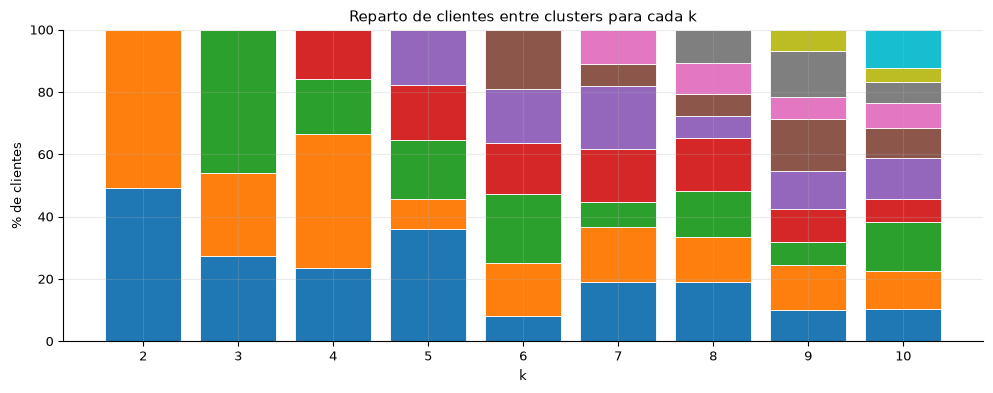

In [5]:
# Tamaño de cada cluster (% de clientes) para cada k
tam = pd.DataFrame({k: pd.Series(np.bincount(m["kmeans"].labels_) / len(X_in) * 100) for k, m in modelos.items()}).T
tam.index.name = "k"; tam.columns = [f"c{i}" for i in tam.columns]
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(tam))
for c in tam.columns:
    v = tam[c].fillna(0).to_numpy()
    ax.bar(tam.index, v, bottom=bottom, edgecolor="white", linewidth=.6)
    bottom += v
ax.set_xlabel("k"); ax.set_ylabel("% de clientes"); ax.set_xticks(list(K_RANGE))
ax.set_title("Reparto de clientes entre clusters para cada k")
plt.tight_layout(); plt.show()

**Lectura:** la inercia (suma de distancias al cuadrado de cada cliente a su centroide) **siempre baja al aumentar k**, así que por sí sola no
sirve para elegir k; la usaremos en el **método del codo** para ver a partir de qué k deja de bajar de forma apreciable, y lo contrastaremos con el
**Silhouette Score**. La tabla también muestra si algún k genera clusters residuales (muy pequeños), que serían poco accionables para marketing.

## 4. Método del codo

Se representa la **inercia** frente a k. Al principio, cada cluster nuevo separa grupos de clientes realmente distintos y la inercia cae mucho;
a partir de cierto k solo parte grupos ya homogéneos y la curva se aplana. Ese punto de inflexión es el **codo**.

Para no elegirlo "a ojo" se usan dos medidas:
* **Mejora vs. k−1**: cuánto baja la inercia (%) al añadir un cluster más.
* **Distancia a la recta** que une el primer y el último punto (k = 2 y k = 10), con ambos ejes normalizados a [0, 1] (criterio *kneedle*).
  El codo es el k **más alejado** de esa recta.

In [6]:
codo = P.elbow_table(modelos)
k_codo = P.elbow_k(modelos)
display(codo.style.format({"inercia": "{:,.0f}", "mejora vs k-1 (%)": "{:.1f}", "distancia a la recta": "{:.3f}"})
        .highlight_max(subset=["distancia a la recta"], color="#d6e4f0"))
print(f"k del codo: {k_codo}")

,inercia,mejora vs k-1 (%),distancia a la recta
k,,,
2,"1,021,461",nan,0.000
3,"875,622",14.3,0.148
4,"770,785",12.0,0.220
5,"680,404",11.7,0.265
6,"625,785",8.0,0.242
7,"583,361",6.8,0.196
8,"545,326",6.5,0.143
9,"511,677",6.2,0.081
10,"488,150",4.6,0.000


k del codo: 5


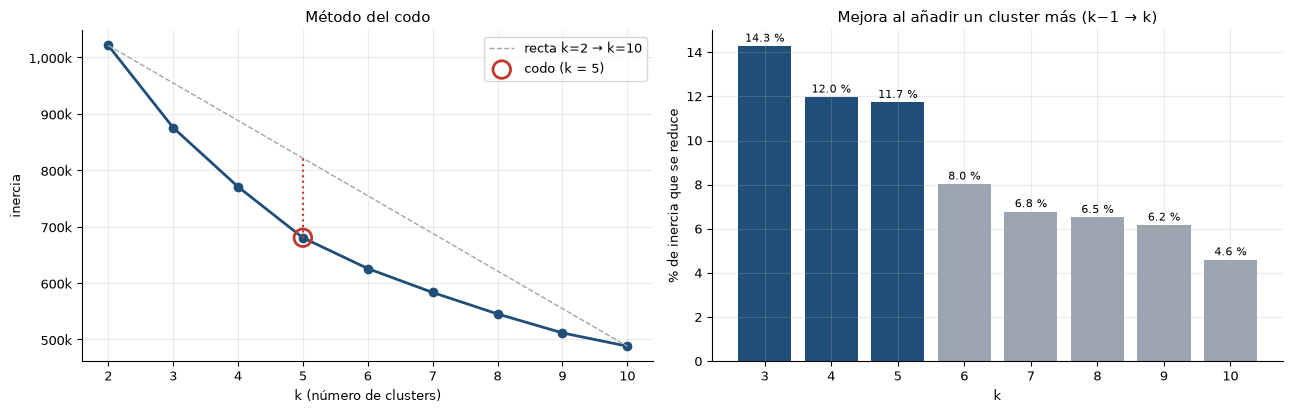

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ks = codo.index.to_numpy()

ax1.plot(ks, codo["inercia"], "o-", color=BLUE, lw=2)
ax1.plot([ks[0], ks[-1]], codo["inercia"].iloc[[0, -1]], ls="--", color=GREY, lw=1, label="recta k=2 → k=10")
ax1.vlines(k_codo, codo["inercia"].loc[k_codo],
           np.interp(k_codo, [ks[0], ks[-1]], codo["inercia"].iloc[[0, -1]]), color=RED, ls=":", lw=1.5)
ax1.scatter([k_codo], [codo["inercia"].loc[k_codo]], s=160, facecolors="none", edgecolors=RED, lw=2, zorder=3,
            label=f"codo (k = {k_codo})")
ax1.set_xlabel("k (número de clusters)"); ax1.set_ylabel("inercia"); ax1.set_xticks(ks)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k"))
ax1.set_title("Método del codo"); ax1.legend()

mej = codo["mejora vs k-1 (%)"].dropna()
ax2.bar(mej.index, mej, color=[BLUE if k <= k_codo else GREY for k in mej.index])
for k, v in mej.items():
    ax2.text(k, v + .2, f"{v:.1f} %", ha="center", fontsize=8)
ax2.set_xlabel("k"); ax2.set_ylabel("% de inercia que se reduce"); ax2.set_xticks(mej.index)
ax2.set_title("Mejora al añadir un cluster más (k−1 → k)")
plt.tight_layout(); plt.show()

**Lectura:** el codo está en **k = 5**.

* De 2 a 5 clusters, cada cluster adicional reduce la inercia entre un **12 % y un 14 %**.
* A partir de k = 6 la mejora cae al **8 %** y después se estanca en torno al **6 %**: añadir más clusters solo subdivide grupos que ya eran homogéneos.
* k = 5 es también el punto más alejado de la recta (distancia 0,265), seguido de cerca por k = 6 (0,242) y k = 4 (0,220).

El codo es un criterio orientativo (la curva es suave, no tiene un quiebro brusco), así que **k = 4, 5 y 6** quedan como candidatos y se
contrastarán con el **Silhouette Score** antes de fijar el k final. Con k = 5 el cluster más pequeño reúne el 9,4 % de los clientes,
un tamaño suficiente para ser accionable en marketing.

## 5. Silhouette Score para cada k

El Silhouette Score mide, para cada cliente, si está más cerca de los de su cluster que de los del cluster vecino. Va de **−1 a 1**:

* cerca de **1**: clusters compactos y bien separados;
* cerca de **0**: el cliente está en la frontera entre dos clusters;
* **negativo**: estaría mejor en otro cluster.

Se calcula en el **espacio escalado** (después de `log1p` y `StandardScaler`), que es donde K-Means mide las distancias, no sobre las variables originales.
Con 173.456 clientes el cálculo completo no es viable (el coste crece con el cuadrado del número de filas), así que se usa una **muestra fija de
10.000 clientes, la misma para todos los k**: así las diferencias entre scores se deben al número de clusters y no a haber medido clientes distintos.

In [8]:
sil = P.silhouette_scores(modelos, X_in)
k_sil = int(sil.idxmax())
tabla_sil = sil.to_frame()
tabla_sil["candidato del codo"] = np.where(tabla_sil.index == k_codo, "← codo", "")
display(tabla_sil.style.format({"silhouette": "{:.3f}"}).highlight_max(subset=["silhouette"], color="#d6e4f0"))
print(f"Mejor Silhouette Score: k = {k_sil} ({sil.max():.3f})")
print("Candidatos del codo:", ", ".join(f"k={k} → {sil.loc[k]:.3f}" for k in (4, 5, 6)))

,silhouette,candidato del codo
k,,
2,0.173,
3,0.191,
4,0.216,
5,0.228,← codo
6,0.201,
7,0.220,
8,0.213,
9,0.227,
10,0.231,


Mejor Silhouette Score: k = 10 (0.231)
Candidatos del codo: k=4 → 0.216, k=5 → 0.228, k=6 → 0.201


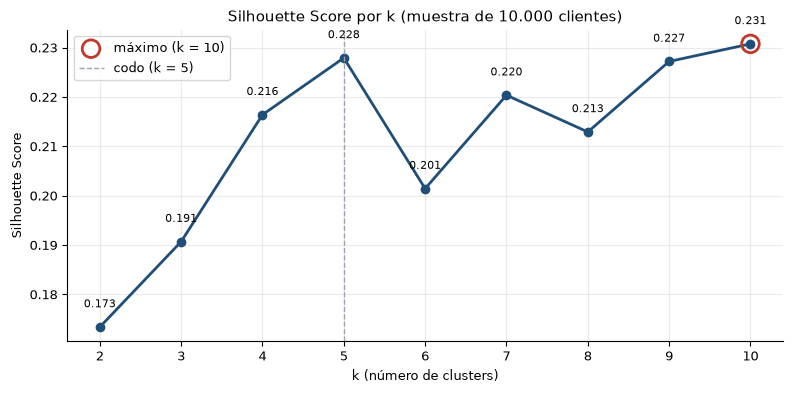

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sil.index, sil.values, "o-", color=BLUE, lw=2)
ax.scatter([k_sil], [sil.loc[k_sil]], s=160, facecolors="none", edgecolors=RED, lw=2, zorder=3,
           label=f"máximo (k = {k_sil})")
ax.axvline(k_codo, color=GREY, ls="--", lw=1, label=f"codo (k = {k_codo})")
for k, v in sil.items():
    ax.text(k, v + .004, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xlabel("k (número de clusters)"); ax.set_ylabel("Silhouette Score"); ax.set_xticks(list(sil.index))
ax.set_title("Silhouette Score por k (muestra de 10.000 clientes)")
ax.legend(); plt.tight_layout(); plt.show()

**Lectura (muestra de 10.000 clientes):**

| k | 2 | 3 | 4 | **5** | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|
| Silhouette | 0,173 | 0,191 | 0,216 | **0,228** | 0,201 | 0,220 | 0,213 | 0,227 | 0,231 |

* El máximo estricto es **k = 10 (0,231)**, pero solo supera a k = 5 en 0,003: la curva sube muy poco a partir de ahí y no justifica duplicar el número de segmentos.
* De los candidatos del codo, **k = 5 es el mejor** (0,228), por delante de k = 4 (0,216) y de k = 6 (0,201, que además es un bache de la curva).
* Los valores son modestos (en torno a 0,2), lo habitual cuando los clientes forman grupos que se solapan y no nubes separadas. El silhouette sirve aquí para **comparar k**, no como una nota absoluta.

Los candidatos razonables del codo son **k = 4, 5 y 6**; la decisión final se documenta en la sección 6.

## 6. Selección y justificación del número óptimo de clusters

Entregable del reto 3: **qué k elegimos** y **por qué**, cruzando método del codo, Silhouette Score y tamaño mínimo de cada segmento
(un cluster demasiado pequeño no es accionable para marketing).

In [10]:
sel = P.k_selection_table(modelos, codo, sil)
k_final = P.choose_k(k_codo, sil)
sel["← k elegido"] = np.where(sel.index == k_final, "✓", "")
display(sel.style.format({
    "inercia": "{:,.0f}", "mejora vs k-1 (%)": "{:.1f}", "distancia a la recta": "{:.3f}",
    "silhouette (muestra 10k)": "{:.3f}", "cluster más pequeño (%)": "{:.1f}", "cluster mayor (%)": "{:.1f}",
}).highlight_max(subset=["distancia a la recta"], color="#d6e4f0")
      .highlight_max(subset=["silhouette (muestra 10k)"], color="#fde8e8"))
print(f"\n>>> k óptimo elegido: {k_final}")

,inercia,iteraciones,cluster más pequeño (%),cluster mayor (%),mejora vs k-1 (%),distancia a la recta,silhouette (muestra 10k),← k elegido
k,,,,,,,,
2,"1,021,461",11,49.1,50.9,nan,0.000,0.173,
3,"875,622",12,26.5,46.1,14.3,0.148,0.191,
4,"770,785",17,15.8,43.1,12.0,0.220,0.216,
5,"680,404",30,9.4,36.2,11.7,0.265,0.228,✓
6,"625,785",25,8.2,22.1,8.0,0.242,0.201,
7,"583,361",19,7.2,20.3,6.8,0.196,0.220,
8,"545,326",29,6.9,18.9,6.5,0.143,0.213,
9,"511,677",44,6.7,16.9,6.2,0.081,0.227,
10,"488,150",24,4.5,15.6,4.6,0.000,0.231,



>>> k óptimo elegido: 5


### Decisión: **k = 5**

| Criterio | Resultado | Interpretación |
|---|---|---|
| **Método del codo** | k = 5 (distancia a la recta **0,265**, la mayor) | A partir de k = 6 la inercia solo baja ~8 % por cluster nuevo (frente a 12–14 % entre k = 2 y 5): subdividir más aporta poco. |
| **Silhouette Score** | **0,228** en k = 5 (máximo entre k = 4–6) | Mejor separación relativa entre los candidatos del codo; k = 6 cae a 0,201. El máximo global (k = 10, 0,231) mejora solo **0,003** y no compensa 10 segmentos. |
| **Tamaño de clusters** | El más pequeño: **9,4 %** (cluster 1) | Ningún segmento queda residual (<5 %); todos son utilizables en campañas. |
| **Negocio** | 5 perfiles distintos | Suficiente granularidad para ofertas diferenciadas sin fragmentar la base en demasiados grupos. |

**Descartados:** k = 2–3 agrupan demasiado (poca personalización); k ≥ 7 mejoran métricas de forma marginal y generan clusters más pequeños o redundantes; k = 10 maximiza el silhouette de forma irrelevante (+0,003 vs k = 5).

El modelo final (sección 7) usa **k = 5** y el pipeline `modelos[5]` ya ajustado sobre los 173.456 clientes.

In [11]:
OUT = P.OUTPUT_DIR
OUT.mkdir(parents=True, exist_ok=True)
path_sel = OUT / "seleccion_k_justificacion.csv"
sel.assign(k_elegido=k_final).reset_index().to_csv(path_sel, index=False, encoding="utf-8-sig")
print("Tabla de selección guardada en", path_sel)

Tabla de selección guardada en C:\Users\1010a\Documents\UMA\Malackathon1\Backend\clustering\output\seleccion_k_justificacion.csv


## 7. Modelo final y distribución de clientes

Con **k = 5** fijado por el codo y confirmado por el mejor silhouette entre los candidatos (4–6), el **modelo final** es el pipeline ya entrenado
sobre **todos los clientes** en la sección 3 (`modelos[k_final]`). No hace falta volver a ajustar: es el mismo objeto que usamos para comparar k,
ahora reutilizado para asignar el segmento de cada cliente.

Salidas:
* tabla y gráfico de **distribución** (% de clientes por cluster);
* `clustering/output/clientes_segmentados.parquet` (features + descriptivos + `cluster`);
* `clustering/output/kmeans_pipeline_k5.joblib` (pipeline completo para scoring de clientes nuevos).

In [12]:
modelo_final = modelos[k_final]
km = modelo_final["kmeans"]

clientes = P.label_clients(modelo_final, X_df)
dist = P.cluster_distribution(clientes["cluster"])
dist.index.name = "cluster"

print(f"Modelo final: k = {k_final}  |  inercia = {km.inertia_:,.0f}  |  iteraciones = {km.n_iter_}")
print(f"Total clientes segmentados: {len(clientes):,}\n")

Modelo final: k = 5  |  inercia = 680,404  |  iteraciones = 30
Total clientes segmentados: 173,456



### Distribución de clientes por cluster

Entregable del reto 3: cuántos clientes caen en cada segmento (k = 5). La suma debe ser el 100 % de la base (173.456 clientes).

In [13]:
tabla_dist = dist.copy()
tabla_dist.index = [f"Cluster {i}" for i in tabla_dist.index]
display(tabla_dist.style.format({"n_clientes": "{:,.0f}", "pct_clientes": "{:.2f}", "pct_acumulado": "{:.2f}"})
        .set_caption("Distribución de clientes por cluster"))
print(tabla_dist.to_string(float_format=lambda v: f"{v:,.2f}"))
assert abs(tabla_dist["pct_clientes"].sum() - 100) < 0.01, "Los % deben sumar 100"

,n_clientes,pct_clientes,pct_acumulado
Cluster 0,"62,706",36.15,36.15
Cluster 1,"16,334",9.42,45.57
Cluster 2,"33,069",19.06,64.63
Cluster 3,"30,767",17.74,82.37
Cluster 4,"30,580",17.63,100.00


           n_clientes  pct_clientes  pct_acumulado
Cluster 0       62706         36.15          36.15
Cluster 1       16334          9.42          45.57
Cluster 2       33069         19.06          64.63
Cluster 3       30767         17.74          82.37
Cluster 4       30580         17.63         100.00


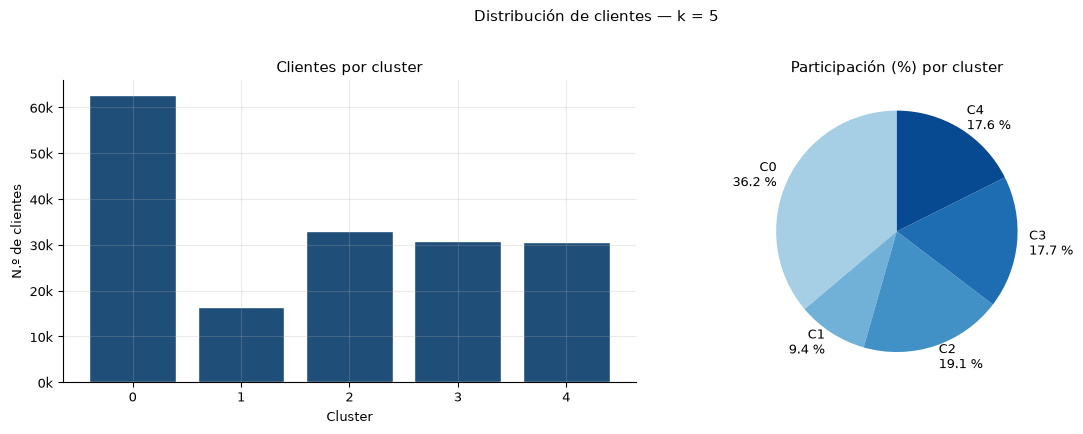

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
labels = [f"C{i}\n{row.pct_clientes:.1f} %" for i, row in dist.iterrows()]
ax1.bar(dist.index.astype(str), dist["n_clientes"], color=BLUE, edgecolor="white")
ax1.set_xlabel("Cluster"); ax1.set_ylabel("N.º de clientes")
ax1.set_title("Clientes por cluster"); ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))

w = dist["pct_clientes"]
ax2.pie(w, labels=labels, autopct="", startangle=90, colors=plt.cm.Blues(np.linspace(.35, .9, len(w))))
ax2.set_title("Participación (%) por cluster")
plt.suptitle(f"Distribución de clientes — k = {k_final}", y=1.02)
plt.tight_layout(); plt.show()

In [15]:
import joblib

OUT = P.OUTPUT_DIR
OUT.mkdir(parents=True, exist_ok=True)
path_pipe = OUT / f"kmeans_pipeline_k{k_final}.joblib"
path_datos = OUT / "clientes_segmentados.parquet"
path_dist = OUT / "distribucion_clusters.csv"
joblib.dump(modelo_final, path_pipe)
clientes.to_parquet(path_datos, index=False)
dist.reset_index().to_csv(path_dist, index=False, encoding="utf-8-sig")
print("Guardado:", path_pipe)
print("Guardado:", path_datos, f"({len(clientes):,} filas)")
print("Guardado:", path_dist)

Guardado: C:\Users\1010a\Documents\UMA\Malackathon1\Backend\clustering\output\kmeans_pipeline_k5.joblib
Guardado: C:\Users\1010a\Documents\UMA\Malackathon1\Backend\clustering\output\clientes_segmentados.parquet (173,456 filas)
Guardado: C:\Users\1010a\Documents\UMA\Malackathon1\Backend\clustering\output\distribucion_clusters.csv


**Lectura:** los cinco segmentos tienen tamaños **accionables** para marketing: el más pequeño (cluster 1) reúne el **9,4 %** de los clientes;
el más grande (cluster 0) el **36,2 %**; el resto ronda el 17–19 %. Los perfiles de cada cluster se describen en el reto 4 (interpretación).

Ver la **justificación completa de k** en la sección 6.

## 8. Perfil del cliente por cluster (reto 4)

Cada cluster se describe en **lenguaje de negocio** con las variables que entraron en el modelo (medias) y las descriptivas que guardamos
(género, país, segmento 1 vehículo / multi / flota, telemetría). Los nombres de segmento resumen el rasgo más distintivo frente al resto de la base.

| Cluster | Nombre | Tamaño |
|---:|---|---|
| 0 | Particular estable | ~36 % |
| 1 | Multi-vehículo fiel | ~9 % |
| 2 | Leasing electrificado | ~19 % |
| 3 | Senior electrificado | ~18 % |
| 4 | Premium tradicional | ~18 % |

In [16]:
perfil = P.profile_summary_table(clientes)
display(perfil.drop(columns=["resumen"]).set_index(["cluster", "nombre_segmento"]))
for _, row in perfil.iterrows():
    print(f"\nCluster {int(row.cluster)} — {row.nombre_segmento} ({row.pct_clientes:.1f} %)")
    print(f"  {row.resumen}")

,,n_clientes,pct_clientes,Edad (punto medio del rango),Meses como cliente MB,N.º vehículos (tope 10),Antigüedad vehículos (años),Cuota electrificados (0-1),Cuota gama premium (0-1),Tiene leasing activo (0/1)
cluster,nombre_segmento,,,,,,,,,
0,Particular estable,62706,36.15,48.78,31.77,1.14,6.23,0.01,0.01,0.00
1,Multi-vehículo fiel,16334,9.42,51.33,58.70,4.30,5.33,0.31,0.30,0.36
2,Leasing electrificado,33069,19.06,46.50,33.00,1.37,3.44,0.44,0.04,1.00
3,Senior electrificado,30767,17.74,53.40,28.83,1.18,3.99,0.96,0.02,0.00
4,Premium tradicional,30580,17.63,50.05,31.09,1.18,5.66,0.36,0.98,0.21



Cluster 0 — Particular estable (36.1 %)
  Un solo vehículo, baja electrificación, perfil medio de la base.

Cluster 1 — Multi-vehículo fiel (9.4 %)
  Varios vehículos o mini-flota, mucha antigüedad con la marca y alta telemetría.

Cluster 2 — Leasing electrificado (19.1 %)
  Casi siempre con leasing activo, flota joven y alta cuota de híbridos/eléctricos.

Cluster 3 — Senior electrificado (17.7 %)
  Clientes mayores con parque muy electrificado y vehículos relativamente nuevos.

Cluster 4 — Premium tradicional (17.6 %)
  Cartera mayoritariamente de gama alta (S/E/GLE/EQS…), electrificación moderada.


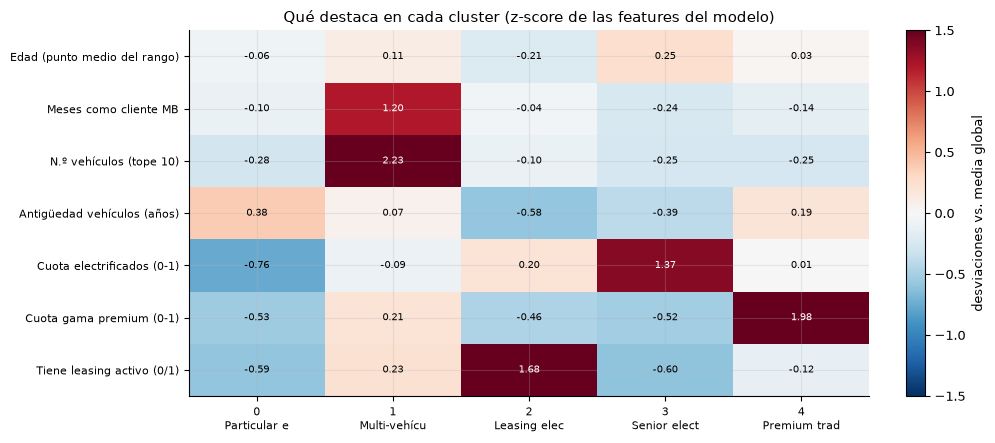

In [17]:
z = P.profile_zscores(clientes)
z.columns = [P.FEATURE_LABELS[c] for c in z.columns]
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(z.T, aspect="auto", cmap="RdBu_r", vmin=-1.5, vmax=1.5)
ax.set_xticks(range(len(z)))
ax.set_xticklabels([f"{i}\n{P.CLUSTER_NAMES[i][:12]}" for i in z.index], fontsize=8)
ax.set_yticks(range(len(z.columns)))
ax.set_yticklabels(z.columns, fontsize=8)
for i in range(len(z.columns)):
    for j in range(len(z)):
        ax.text(j, i, f"{z.iloc[j, i]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(z.iloc[j, i]) > 0.9 else "black")
plt.colorbar(im, ax=ax, fraction=.03, label="desviaciones vs. media global")
ax.set_title("Qué destaca en cada cluster (z-score de las features del modelo)")
plt.tight_layout(); plt.show()

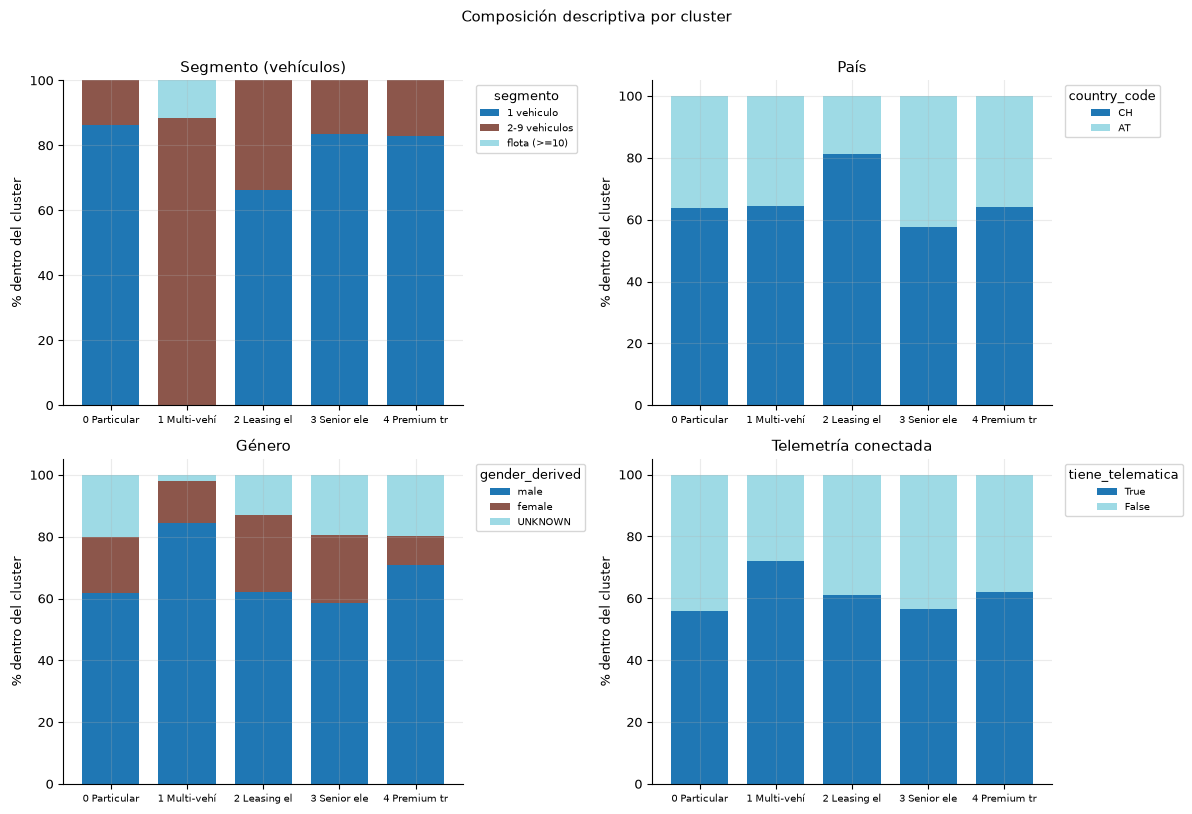

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
cats = [("segmento", "Segmento (vehículos)"), ("country_code", "País"),
        ("gender_derived", "Género"), ("tiene_telematica", "Telemetría conectada")]
for ax, (col, tit) in zip(axes.ravel(), cats):
    t = P.profile_categorical(clientes, col)
    t.index = [f"{i} {P.CLUSTER_NAMES[i][:10]}" for i in t.index]
    t.plot(kind="bar", stacked=True, ax=ax, width=.75, colormap="tab20")
    ax.set_title(tit); ax.set_xlabel(""); ax.set_ylabel("% dentro del cluster")
    ax.legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
    ax.tick_params(axis="x", rotation=0, labelsize=7)
plt.suptitle("Composición descriptiva por cluster", y=1.01)
plt.tight_layout(); plt.show()

In [19]:
path_perfil = OUT / "perfil_clusters.csv"
perfil.to_csv(path_perfil, index=False, encoding="utf-8-sig")
clientes["nombre_segmento"] = clientes["cluster"].map(P.CLUSTER_NAMES)
clientes.to_parquet(OUT / "clientes_segmentados.parquet", index=False)
print("Guardado:", path_perfil)

Guardado: C:\Users\1010a\Documents\UMA\Malackathon1\Backend\clustering\output\perfil_clusters.csv


### Perfiles para marketing

**0 — Particular estable (36 %)**  
Un vehículo de media, electrificación casi nula y sin leasing. Es el “cliente tipo” de la base: propietario OWNER, edad y antigüedad medias.
Acciones: mantenimiento programado, accesorios, upgrade gradual hacia mild hybrid.

**1 — Multi-vehículo fiel (9 %)**  
~4 vehículos de media, **58 meses** con la marca (el doble que la base) y 11 % mini-flotas. Más telemetría conectada.
Acciones: contratos marco de flota, leasing corporativo, servicios prioritarios.

**2 — Leasing electrificado (19 %)**  
**100 %** con leasing activo, vehículos más jóvenes (~3,4 años) y **44 %** de parque electrificado; fuerte peso en Suiza.
Acciones: renovación de contrato, ofertas EQ/ plug-in, cargadores y tarifas energía.

**3 — Senior electrificado (18 %)**  
Edad media más alta (~53) y **96 %** de vehículos electrificados/híbridos en su parque; poco leasing.
Acciones: movilidad eléctrica premium, taller y garantía, formación digital.

**4 — Premium tradicional (18 %)**  
**98 %** de vehículos de gama alta (Clase S/E/GLE/EQS/AMG…); electrificación moderada (~36 %).
Acciones: modelos flagship, personalización AMG/Maybach, eventos exclusivos.

Estos nombres y acciones son orientativos para la presentación; conviene validarlos con negocio Mercedes antes de campañas reales.